In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.helpers.output_index import drawdown, sharpe
#from src.utility.generate_datasets import create_df
from src.helpers.download_prices import prices

In [2]:
# Specify the base directory containing all the action directories
base_dir = 'D:/TCC Lucas/vulture_ai_laboratory/models/basic/'  # Replace with your base directory if different

# Initialize an empty list to store data
data_list = []
v = ['v1.0', 'v2.0', 'v3.0']
#v = ['v2.0']

start_valid = pd.Timestamp(year=2019, month=12, day=10).strftime("%Y-%m-%d")
end_valid = pd.Timestamp(year=2021, month=12, day=30).strftime("%Y-%m-%d")

try:
    df = pd.read_excel('./results_tcc/valid_data.xlsx')
except:
    for version in v:
        if version=='v1.0':
            algoritmo = 'xgboost'
        elif version=='v2.0':
            algoritmo = 'randomforest'
        else:
            algoritmo = 'svm'
        # Walk through the directory structure
        for root, dirs, files in os.walk(base_dir):
            if root[-4:]!=version:
                continue
            for file in files:
                if file == 'report.json':
                    file_path = os.path.join(root, file)
                    with open(file_path, 'r') as f:
                        data = json.load(f)

                        # Computing drawdown for validation
                        tickers = {data.get('ticker'): ["Open", "High", "Low", "Close", "Volume"],}
                        data_valid = data.get('data_valid')
                        start = data_valid[0]
                        end = data_valid[-1]
                        dados = prices(tickers, start, end, interval="1d", update=True)
                        dados.dropna(inplace=True)
                        dados.reset_index()
                        # data, ticker, preds, qtd=1, percent=True, days=1
                        #print(start, start_valid, end, end_valid)
                        try:
                            drawdown_ibov, drawdown_model = drawdown(data=dados, ticker=data.get('ticker'), preds=data.get('classification_valid'), percent=True)
                        except:
                            drawdown_ibov, drawdown_model = pd.Series(np.zeros(len(dados))), pd.Series(np.zeros(len(dados)))

                        # Extract necessary fields
                        data_entry = {
                            'algoritmo': algoritmo,

                            'ticker': data.get('ticker'),
                            #"data_test": data.get('data'),
                            'sharpe': data.get('sharpe'),
                            'sharpe_model': data.get('sharpe_model'),                        
                            'percent_return_cumsum': data.get('percent_return_cumsum'),
                            'percent_return_model_cumsum': data.get('percent_return_model_cumsum'),
                            'max_dd': data.get('max_dd'),
                            'max_dd_model': data.get('max_dd_model'),
                            
                            #"data_valid": data.get('data_valid'),
                            'sharpe_valid': data.get('sharpe_valid'),
                            'sharpe_valid_model': data.get('sharpe_valid_model'),
                            'percent_return_valid_cumsum': data.get('percent_return_valid_cumsum'),
                            'percent_return_model_valid_cumsum': data.get('percent_return_model_valid_cumsum'),
                            'max_dd_valid': drawdown_ibov.values.min(),
                            'max_dd_valid_model': drawdown_model.values.min(),
                            #"target_valid": data.get('target_valid'),
                            #"classification_valid": data.get('classification_valid'),
                            #"percent_return_valid": data.get('percent_return_valid'),
                            
                            
                        }
                        data_list.append(data_entry)

    # Create a DataFrame from the collected data
    df = pd.DataFrame(data_list)
    # Set 'ticker' as the index
    df.set_index('ticker', inplace=True)
    df.to_excel('./results_tcc/valid_data.xlsx')


Requested update vulture datasets: ABEV3.SA
Requested update vulture datasets: ALPA4.SA
Requested update vulture datasets: AZUL4.SA
Requested update vulture datasets: AZZA3.SA
Requested update vulture datasets: B3SA3.SA
Requested update vulture datasets: BBAS3.SA
Requested update vulture datasets: BBDC3.SA
Requested update vulture datasets: BBDC4.SA
Requested update vulture datasets: BBSE3.SA
Requested update vulture datasets: BEEF3.SA
Requested update vulture datasets: BPAC11.SA
Requested update vulture datasets: BRAP4.SA
Requested update vulture datasets: BRFS3.SA
Requested update vulture datasets: BRKM5.SA
Requested update vulture datasets: CCRO3.SA
Requested update vulture datasets: CMIG4.SA
Requested update vulture datasets: COGN3.SA
Requested update vulture datasets: CPFE3.SA
Requested update vulture datasets: CPLE6.SA
Requested update vulture datasets: CRFB3.SA
Requested update vulture datasets: CSAN3.SA
Requested update vulture datasets: CSNA3.SA
Requested update vulture datase

In [3]:
tickers = {'BOVA11.SA': ["Open", "High", "Low", "Close", "Volume"],}
#data_valid = data.get('data_valid')
start = data_valid[0]
end = data_valid[-1]
bova11 = prices(tickers, start, end, interval="1d", update=False)
bova11['percent_return'] = bova11['Close_BOVA11.SA'].pct_change()

return_valid_cumsum_bova11 = 100*bova11['percent_return'].sum().item()
sharpe_bova11_valid= sharpe(bova11['percent_return'], len(bova11), 10.75 / 100).item()

bova11.dropna(inplace=True)
bova11.reset_index(inplace=True)

start = data.get('data')[0] #data_valid[-1]
now = pd.Timestamp(year=2024, month=10, day=10)
end = data.get('data')[-1] # now.strftime("%Y-%m-%d")
bova11_test = prices(tickers, start, end, interval="1d", update=False)
bova11_test['percent_return'] = bova11_test['Close_BOVA11.SA'].pct_change()

return_cumsum_bova11 = 100*bova11_test['percent_return'].sum().item()
sharpe_bova11= sharpe(bova11_test['percent_return'], len(bova11_test), 10.75 / 100).item()

bova11_test.dropna(inplace=True)
bova11_test.reset_index(inplace=True)

drawdown_ibov, _ = drawdown(bova11_test, 'BOVA11.SA', data.get('classification'), data.get('best_percentual'), True)

Direct request from vulture datasets: BOVA11.SA
Direct request from vulture datasets: BOVA11.SA


In [4]:
print(f"BOVA11 - Retorno Acumulado: {return_valid_cumsum_bova11}, Sharpe: {sharpe_bova11_valid} (valid)")
print(f"BOVA11 - Retorno Acumulado: {return_cumsum_bova11}, Sharpe: {sharpe_bova11} (test)")

BOVA11 - Retorno Acumulado: 2.082849428624567, Sharpe: -0.1789208524575735 (valid)
BOVA11 - Retorno Acumulado: 20.87490001723127, Sharpe: 0.3403572552686325 (test)


In [5]:
# Regra de decisão: sharpe do modelo na validação > limiar (análise dos quartis) e drawdown maximo do modelo na validação > que o DD do papel

limiar_svm = 0.66
limiar_xg = 0.8
limiar_rf = 0.72

# SVM
df_filtered = df[df['sharpe_valid_model']>limiar_svm].sort_values(by='sharpe_valid_model', ascending=False)
df_filtered = df_filtered[df_filtered['max_dd_valid_model']>df_filtered['max_dd_valid']]

# Random Forest
df_filtered2 = df[df['sharpe_valid_model']>limiar_rf].sort_values(by='sharpe_valid_model', ascending=False)
df_filtered2 = df_filtered2[df_filtered2['max_dd_valid_model']>df_filtered2['max_dd_valid']]

# XGBoost
df_filtered3 = df[df['sharpe_valid_model']>limiar_xg].sort_values(by='sharpe_valid_model', ascending=False)
df_filtered3 = df_filtered3[df_filtered3['max_dd_valid_model']>df_filtered3['max_dd_valid']]

#df_default = df[df['sharpe_valid']>1].sort_values(by='sharpe_valid', ascending=False)
#df_default = df_default[df_default['max_dd_valid_model']<df_default['max_dd_valid']]

In [6]:
#randomforest_df = df_filtered[df_filtered['algoritmo']=='randomforest']
#xgboost_df = df_filtered[df_filtered['algoritmo']=='xgboost']
#svm_df = df_filtered[df_filtered['algoritmo']=='svm']


randomforest_df = df_filtered2[df_filtered2['algoritmo']=='randomforest']
xgboost_df = df_filtered3[df_filtered3['algoritmo']=='xgboost']
svm_df = df_filtered[df_filtered['algoritmo']=='svm']

#randomforest_df_default = df_default[df_default['algoritmo']=='randomforest']
#xgboost_df_default = df_default[df_default['algoritmo']=='xgboost']
#svm_df_default = df_default[df_default['algoritmo']=='svm']

In [7]:
print("RF -      Max DD:", randomforest_df['max_dd_model'].mean().round(3).item(), " || Papeis - Max DD:", randomforest_df['max_dd'].mean().round(3).item())
print("SVM -     Max DD:", svm_df['max_dd_model'].mean().round(3).item(), " || Papeis - Max DD:", svm_df['max_dd'].mean().round(3).item())
print("XGBoost - Max DD:", xgboost_df['max_dd_model'].mean().round(3).item(), " || Papeis - Max DD:", xgboost_df['max_dd'].mean().round(3).item())

RF -      Max DD: -22.812  || Papeis - Max DD: -36.273
SVM -     Max DD: -27.681  || Papeis - Max DD: -36.563
XGBoost - Max DD: -22.095  || Papeis - Max DD: -40.478


In [8]:
print("RF -      Sharpe:", randomforest_df['sharpe_model'].mean().round(3).item(), " || Papeis - Sharpe:", randomforest_df['sharpe'].mean().round(3).item())
print("SVM -     Sharpe:", svm_df['sharpe_model'].mean().round(3).item(), " || Papeis - Sharpe:", svm_df['sharpe'].mean().round(3).item())
print("XGBoost - Sharpe:", xgboost_df['sharpe_model'].mean().round(3).item(), " || Papeis - Sharpe:", xgboost_df['sharpe'].mean().round(3).item())

RF -      Sharpe: 0.947  || Papeis - Sharpe: 0.497
SVM -     Sharpe: 0.238  || Papeis - Sharpe: 0.516
XGBoost - Sharpe: 0.411  || Papeis - Sharpe: 0.588


In [9]:
print("RF -      Retorno:", randomforest_df['percent_return_model_cumsum'].sum().round(3).item(), "  || Papeis - Retorno:", randomforest_df['percent_return_cumsum'].sum().round(3).item())
print("SVM -     Retorno:", svm_df['percent_return_model_cumsum'].sum().round(3).item(), "  || Papeis - Retorno:", svm_df['percent_return_cumsum'].sum().round(3).item())
print("XGBoost - Retorno:", xgboost_df['percent_return_model_cumsum'].sum().round(3).item(), " || Papeis - Retorno:", xgboost_df['percent_return_cumsum'].sum().round(3).item())

RF -      Retorno: 157.62   || Papeis - Retorno: 194.354
SVM -     Retorno: 229.71   || Papeis - Retorno: 308.472
XGBoost - Retorno: 254.414  || Papeis - Retorno: 436.996


In [10]:
# Extract necessary fields
bova = []
algoritmos = ['svm', 'randomforest', 'xgboost']
for algo in algoritmos:
    data_entry = {
        'algoritmo': algo,
        'ticker': 'BOVA11.SA',
        'sharpe': sharpe_bova11,
        'sharpe_model': 0,
        'percent_return_cumsum': return_cumsum_bova11,
        'percent_return_model_cumsum': 0,
        'max_dd': drawdown_ibov.values.min(),
        'max_dd_model': 0,
        
        
        'sharpe_valid': 0,
        'sharpe_valid_model': 0,
        'percent_return_valid_cumsum': 0,
        'percent_return_model_valid_cumsum': 0,
        'max_dd_valid': 0,
        'max_dd_valid_model': 0,
    }
    bova.append(data_entry)
bova = pd.DataFrame(bova)
bova.set_index('ticker', inplace=True)

svm_df = svm_df._append(bova[bova['algoritmo']=='svm'])
randomforest_df = randomforest_df._append(bova[bova['algoritmo']=='randomforest'])
xgboost_df = xgboost_df._append(bova[bova['algoritmo']=='xgboost'])

In [49]:
#np.savetxt('./results_tcc/recomend_rf.txt', list(randomforest_df.index), delimiter=',', fmt='%s')
#np.savetxt('./results_tcc/recomend_svm.txt', list(svm_df.index), delimiter=',', fmt='%s')
#np.savetxt('./results_tcc/recomend_xgboost.txt', list(xgboost_df.index), delimiter=',', fmt='%s')

<Figure size 864x576 with 0 Axes>

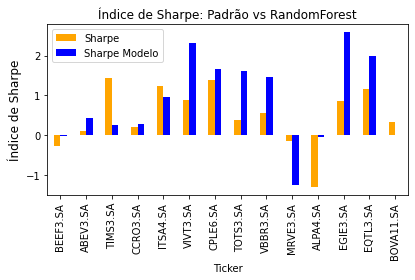

In [11]:
# Plot Sharpe ratios
plt.figure(figsize=(12,8))
#randomforest_df_default['percent_return_cumsum'].plot(kind='bar', color='blue')
randomforest_df.plot(kind='bar', y=['sharpe', 'sharpe_model'], color=['orange', 'blue'])
#randomforest_df['sharpe_model'].plot(kind='bar', color='gray')
plt.title('Índice de Sharpe: Padrão vs RandomForest')
plt.ylabel('Índice de Sharpe', fontsize=12)
plt.xlabel('Ticker')
plt.legend(['Sharpe', 'Sharpe Modelo'])
plt.tight_layout()
#plt.savefig('./results_tcc/sharpe_rf.png', dpi=300)
plt.show()

<Figure size 864x576 with 0 Axes>

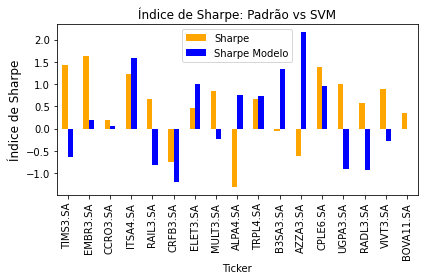

In [12]:
# Plot Sharpe ratios
plt.figure(figsize=(12,8))
svm_df.plot(kind='bar', y=['sharpe', 'sharpe_model'], color=['orange', 'blue'])
plt.title('Índice de Sharpe: Padrão vs SVM')
plt.ylabel('Índice de Sharpe', fontsize=12)
plt.xlabel('Ticker')
plt.legend(['Sharpe', 'Sharpe Modelo'])
plt.tight_layout()
#plt.savefig('./results_tcc/sharpe_svm.png', dpi=300)
plt.show()

<Figure size 864x576 with 0 Axes>

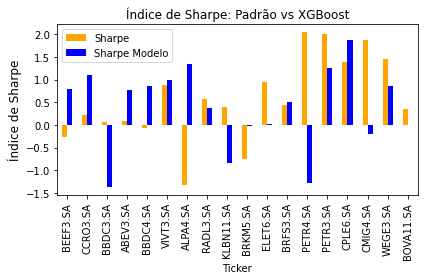

In [13]:
# Plot Sharpe ratios
plt.figure(figsize=(12,8))
xgboost_df.plot(kind='bar', y=['sharpe', 'sharpe_model'], color=['orange', 'blue'])
plt.title('Índice de Sharpe: Padrão vs XGBoost')
plt.ylabel('Índice de Sharpe', fontsize=12)
plt.xlabel('Ticker')
plt.legend(['Sharpe', 'Sharpe Modelo'])
plt.tight_layout()
#plt.savefig('./results_tcc/sharpe_xgboost.png', dpi=300)
plt.show()

<Figure size 864x576 with 0 Axes>

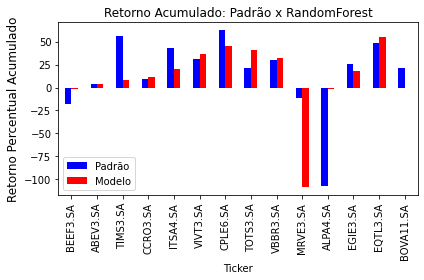

In [14]:
# Plot Retornos Acumulados
plt.figure(figsize=(12,8))
randomforest_df[['percent_return_cumsum','percent_return_model_cumsum']].plot(kind='bar', color=['blue', 'red'])
plt.title('Retorno Acumulado: Padrão x RandomForest')
plt.ylabel('Retorno Percentual Acumulado', fontsize=12)
plt.xlabel('Ticker')
plt.legend(['Padrão', 'Modelo'])
plt.tight_layout()
#plt.savefig('./results_tcc/retorno_rf.png', dpi=300)
plt.show()

<Figure size 864x576 with 0 Axes>

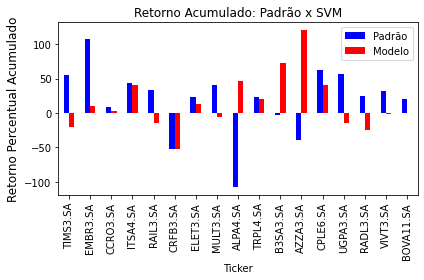

In [15]:
# Plot Retornos Acumulados
plt.figure(figsize=(12,8))
svm_df[['percent_return_cumsum','percent_return_model_cumsum']].plot(kind='bar', color=['blue', 'red'])
plt.title('Retorno Acumulado: Padrão x SVM')
plt.ylabel('Retorno Percentual Acumulado', fontsize=12)
plt.xlabel('Ticker')
plt.legend(['Padrão', 'Modelo'])
plt.tight_layout()
#plt.savefig('./results_tcc/retorno_svm.png', dpi=300)
plt.show()

<Figure size 864x576 with 0 Axes>

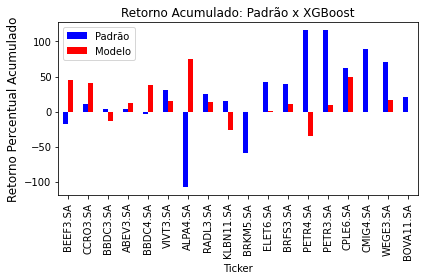

In [16]:
# Plot Retornos Acumulados
plt.figure(figsize=(12,8))
xgboost_df[['percent_return_cumsum','percent_return_model_cumsum']].plot(kind='bar', color=['blue', 'red'])
plt.title('Retorno Acumulado: Padrão x XGBoost')
plt.ylabel('Retorno Percentual Acumulado',fontsize=12)
plt.xlabel('Ticker')
plt.legend(['Padrão', 'Modelo'])
plt.tight_layout()
#plt.savefig('./results_tcc/retorno_xgboost.png', dpi=300)
plt.show()

<Figure size 576x432 with 0 Axes>

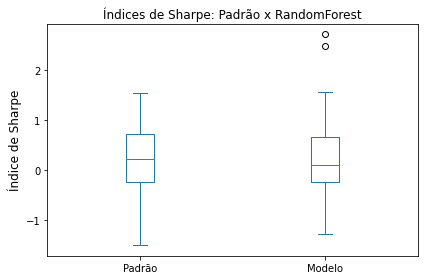

In [17]:
plt.figure(figsize=(8, 6))
df[df['algoritmo']=='randomforest'][['sharpe_valid', 'sharpe_valid_model']].plot(kind='box')
plt.title('Índices de Sharpe: Padrão x RandomForest')
plt.ylabel('Índice de Sharpe', fontsize=12)
plt.xticks((1,2),('Padrão', 'Modelo'))
plt.tight_layout()
#plt.savefig('./results_tcc/box_sharpe_valid_rf.png', dpi=300)
plt.show()

<Figure size 576x432 with 0 Axes>

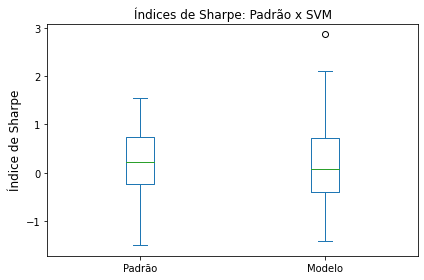

In [18]:
plt.figure(figsize=(8, 6))
df[df['algoritmo']=='svm'][['sharpe_valid', 'sharpe_valid_model']].plot(kind='box')
plt.title('Índices de Sharpe: Padrão x SVM')
plt.ylabel('Índice de Sharpe', fontsize=12)
plt.xticks((1,2),('Padrão', 'Modelo'))
plt.tight_layout()
#plt.savefig('./results_tcc/box_sharpe_valid_svm.png', dpi=300)
plt.show()

<Figure size 576x432 with 0 Axes>

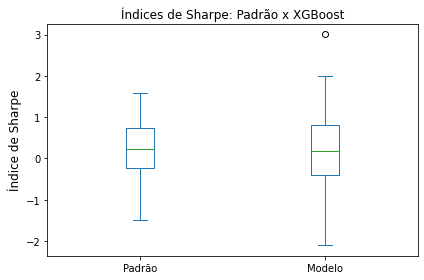

In [19]:
plt.figure(figsize=(8, 6))
df[df['algoritmo']=='xgboost'][['sharpe_valid', 'sharpe_valid_model']].plot(kind='box')
plt.title('Índices de Sharpe: Padrão x XGBoost')
plt.ylabel('Índice de Sharpe', fontsize=12)
plt.xticks((1,2),('Padrão', 'Modelo'))
plt.tight_layout()
#plt.savefig('./results_tcc/box_sharpe_valid_xgboost.png', dpi=300)
plt.show()

In [20]:
# Plot Max Drawdowns
#plt.figure(figsize=(12, 6))
#df[['max_dd', 'max_dd_model']].plot(kind='bar')
#plt.title('Max Drawdown vs Max Drawdown Model per Ticker')
#plt.ylabel('Maximum Drawdown')
#plt.xlabel('Ticker')
#plt.legend(['Max Drawdown', 'Max Drawdown Model'])
#plt.tight_layout()
#plt.show()

<Figure size 576x432 with 0 Axes>

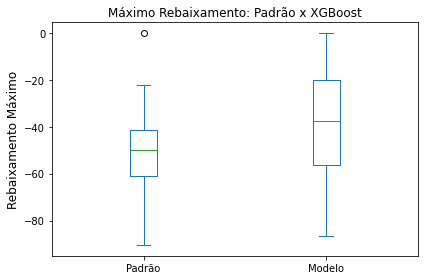

In [21]:
plt.figure(figsize=(8, 6))
df[df['algoritmo']=='xgboost'][['max_dd_valid', 'max_dd_valid_model']].plot(kind='box')
plt.title('Máximo Rebaixamento: Padrão x XGBoost')
plt.ylabel('Rebaixamento Máximo', fontsize=12)
plt.xticks((1,2),('Padrão', 'Modelo'))
plt.tight_layout()
#plt.savefig('./results_tcc/box_dd_valid_xgboost.png', dpi=300)
plt.show()

<Figure size 576x432 with 0 Axes>

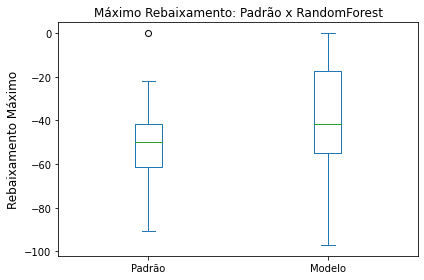

In [22]:
plt.figure(figsize=(8, 6))
df[df['algoritmo']=='randomforest'][['max_dd_valid', 'max_dd_valid_model']].plot(kind='box')
plt.title('Máximo Rebaixamento: Padrão x RandomForest')
plt.ylabel('Rebaixamento Máximo', fontsize=12)
plt.xticks((1,2),('Padrão', 'Modelo'))
plt.tight_layout()
#plt.savefig('./results_tcc/box_dd_valid_rf.png', dpi=300)
plt.show()

<Figure size 576x432 with 0 Axes>

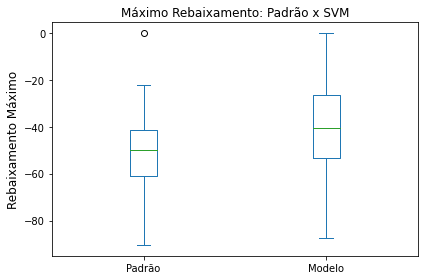

In [23]:
plt.figure(figsize=(8, 6))
df[df['algoritmo']=='svm'][['max_dd_valid', 'max_dd_valid_model']].plot(kind='box')
plt.title('Máximo Rebaixamento: Padrão x SVM')
plt.ylabel('Rebaixamento Máximo', fontsize=12)
plt.xticks((1,2),('Padrão', 'Modelo'))
plt.tight_layout()
#plt.savefig('./results_tcc/box_dd_valid_svm.png', dpi=300)
plt.show()

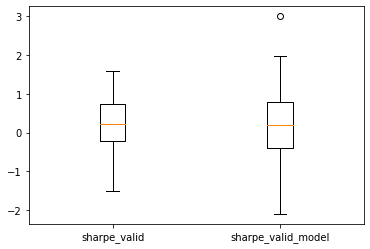

In [24]:

def get_box_plot_data(labels, bp):
    rows_list = []

    for i in range(len(labels)):
        dict1 = {}
        dict1['label'] = labels[i]
        dict1['lower_whisker'] = bp['whiskers'][i*2].get_ydata()[1]
        dict1['lower_quartile'] = bp['boxes'][i].get_ydata()[1]
        dict1['median'] = bp['medians'][i].get_ydata()[1]
        dict1['upper_quartile'] = bp['boxes'][i].get_ydata()[2]
        dict1['upper_whisker'] = bp['whiskers'][(i*2)+1].get_ydata()[1]
        rows_list.append(dict1)

    return pd.DataFrame(rows_list)

box = df[df['algoritmo']=='xgboost'][['sharpe_valid', 'sharpe_valid_model']]

labels = ['sharpe_valid', 'sharpe_valid_model']
bp = plt.boxplot(box, labels=labels)
plt.show()

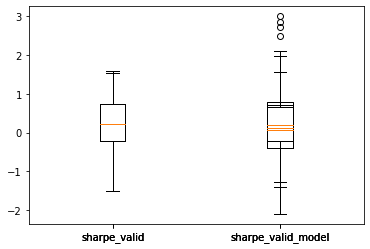

In [25]:
box_xgboost = df[df['algoritmo']=='xgboost'][['sharpe_valid', 'sharpe_valid_model']]
box_randomf = df[df['algoritmo']=='randomforest'][['sharpe_valid', 'sharpe_valid_model']]
box_svm = df[df['algoritmo']=='svm'][['sharpe_valid', 'sharpe_valid_model']]

labels = ['sharpe_valid', 'sharpe_valid_model']

bp = plt.boxplot(box_xgboost, labels=labels)
box_values_xg = get_box_plot_data(labels, bp)

bp = plt.boxplot(box_randomf, labels=labels)
box_values_rf = get_box_plot_data(labels, bp)

bp = plt.boxplot(box_svm, labels=labels)
box_values_svm = get_box_plot_data(labels, bp)

### Vamos analisar os Sharpes dos modelos para descobrir um bom limiar para a escolha de quais papeis vão entrar.

Para isso, pegaremos o terceiro quartil (75%) dos maiores dados como limiar, analisando os 3 modelos para aplicar o mesmo valor de limiar.

A partir dos resultados abaixo, vamos que o quartil de 0.66 (randomforest) é o menor valor dentre os 3 algoritmos, portanto, iremos usar ele de base para criar a seleção de papeis na validação.

In [26]:
box_values_rf

,label,lower_whisker,lower_quartile,median,upper_quartile,upper_whisker
0,sharpe_valid,-1.496317,-0.224887,0.226659,0.732136,1.549054
1,sharpe_valid_model,-1.268508,-0.228128,0.116384,0.659679,1.576266


In [27]:
box_values_svm

,label,lower_whisker,lower_quartile,median,upper_quartile,upper_whisker
0,sharpe_valid,-1.496317,-0.224887,0.226659,0.732136,1.549054
1,sharpe_valid_model,-1.408948,-0.396282,0.078278,0.713837,2.114436


In [28]:
box_values_xg

,label,lower_whisker,lower_quartile,median,upper_quartile,upper_whisker
0,sharpe_valid,-1.496317,-0.224887,0.226659,0.732136,1.585227
1,sharpe_valid_model,-2.103026,-0.396005,0.187078,0.799246,1.990275
